# 8. Partición, desplazamiento y controles de fuga

La propuesta cronológica mantiene entrenamiento, validación y prueba separados. Sólo se muestran distribuciones del objetivo y covariables de entrenamiento/validación. Del tramo de prueba se usan calendario y controles de integridad/procedencia, sin explorar sus valores para decidir preprocesamiento.

KS se presenta como distancia descriptiva sin su p-valor IID; Wasserstein se normaliza con el IQR de entrenamiento. El intervalo de la diferencia de medias usa bootstrap de bloques móviles de 30 días, con 199 réplicas y semilla fija. Supone estabilidad aproximada dentro de cada periodo y se interpreta como diagnóstico.

El diseño de pronóstico considerado utiliza origen diario, contexto de una semana y salida directa de las siguientes 24 horas. Los conteos de ventanas sólo usan calendario: no leen valores de prueba. Los horizontes que atraviesan un corte se purgan. Deben cerrarse las decisiones restantes en un preregistro de benchmark antes de entrenar modelos.


In [1]:
%matplotlib inline
from pathlib import Path

ROOT = next(
    directory for directory in [Path.cwd(), *Path.cwd().parents]
    if (directory / "data/manifest.json").exists()
)

from IPython.display import Markdown, display
import collections
import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from scipy import signal, stats

In [2]:
SEED = 11037
TARGET = 'precio_bolsa_cop_kwh'
RESULTS = ROOT / 'results'
SPLITS = {'train': (2000, 2017), 'validation': (2018, 2021), 'test': (2022, 2025)}
TIME = 'timestamp_start_colombia'
ALLOWED_SOURCES = {'El Tiempo', 'El Espectador', 'Semana', 'Portafolio', 'La República', 'El Colombiano', 'Dinero', 'IDEAM', 'XM'}
RESULTS.mkdir(exist_ok=True)
(RESULTS / 'figures').mkdir(exist_ok=True)
(RESULTS / 'tables').mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (11, 4.4), 'figure.dpi': 110, 'savefig.dpi': 160, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.18, 'axes.prop_cycle': plt.cycler(color=['#245b8d', '#d17a32', '#2b8c77', '#8c5da8', '#9a4949'])})
pd.set_option('display.max_rows', 35)
pd.set_option('display.max_columns', 14)
pd.set_option('display.float_format', lambda x: f'{x:.5g}')

In [3]:
def decision(preprocess, architecture, validation, risk):
    display(Markdown('### Implicaciones del análisis\n\n' + '\n'.join(('- **' + a + ':** ' + b for a, b in [('Preprocesamiento', preprocess), ('Arquitectura', architecture), ('Validación', validation), ('Riesgos', risk)]))))

In [4]:
def figure(fig, name):
    fig.tight_layout()
    fig.savefig(RESULTS / 'figures' / (name + '.png'), bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [5]:
def table(frame, name):
    frame.to_csv(RESULTS / 'tables' / (name + '.csv'), index=True)
    display(frame)
    return None

In [6]:
def load_numeric(split='train', table='hourly', *, allow_test=False):
    if split not in SPLITS:
        raise ValueError('Unknown split')
    if split == 'test' and (not allow_test):
        raise PermissionError('El EDA no puede consultar valores de prueba.')
    a, b = SPLITS[split]
    folder = 'hourly' if table == 'hourly' else 'hydrology'
    frame = pd.concat([pd.read_csv(ROOT / f'data/numeric/{folder}/{year}.csv.gz') for year in range(a, b + 1)], ignore_index=True)
    if table == 'hourly':
        frame.index = pd.DatetimeIndex(pd.to_datetime(frame[TIME], utc=True)).tz_convert('America/Bogota')
    else:
        frame.index = pd.DatetimeIndex(pd.to_datetime(frame['date'])).tz_localize('America/Bogota')
    frame.index.name = 'tiempo_colombia'
    return frame

In [7]:
def split_for_labels(start, end_exclusive):
    start = pd.Timestamp(start)
    end = pd.Timestamp(end_exclusive)
    if start.tzinfo is None or end.tzinfo is None:
        raise ValueError('Se requiere zona horaria.')
    for name, (a, b) in SPLITS.items():
        left = pd.Timestamp(f'{a}-01-01', tz='America/Bogota')
        right = pd.Timestamp(f'{b + 1}-01-01', tz='America/Bogota')
        if left <= start < end <= right:
            return name
    return 'purged'

In [8]:
def aware(value):
    parsed = dt.datetime.fromisoformat(value.replace('Z', '+00:00'))
    if parsed.tzinfo is None:
        raise ValueError('Timestamp must have an explicit timezone')
    return parsed

In [9]:
def eligible(record, origin):
    cutoff = aware(origin)
    if (record.get('source') or record.get('medium')) not in ALLOWED_SOURCES:
        return False
    if record.get('availability_status') != 'verified_archived_version':
        return False
    if record.get('availability_proof') != 'wayback_payload_digest_and_capture':
        return False
    clean_flag = record.get('quarantined', False) in (False, 0, None, '', '0', 'false', 'False')
    if not re.fullmatch('[0-9a-f]{64}', record.get('version_sha256') or '') or not clean_flag:
        return False
    available = record.get('available_at_verified')
    captured = record.get('capture_at_verified')
    if not available or not captured:
        return False
    return aware(captured) <= aware(available) <= cutoff

In [10]:
def eligible_retrospective(record, origin):
    """Escenario autorizado: fecha declarada, SIN certificar versión histórica."""
    cutoff = aware(origin)
    if (record.get('source') or record.get('medium')) not in ALLOWED_SOURCES:
        return False
    if record.get('quarantined', False) not in (False, 0, None, '', '0', 'false', 'False'):
        return False
    assumed = record.get('available_at_assumed')
    if not assumed or record.get('assumed_availability_basis') not in {'declared_timestamp_unverified_version', 'next_day_after_declared_date_unverified_version'}:
        return False
    return aware(assumed) <= cutoff

In [11]:
def select_before_origin(records, origin, scenario='verified'):
    aware(origin)
    if scenario not in {'verified', 'declared_dates'}:
        raise ValueError('Choose verified or declared_dates explicitly')
    rule = eligible if scenario == 'verified' else eligible_retrospective
    field = 'available_at_verified' if scenario == 'verified' else 'available_at_assumed'
    selected = [r for r in records if rule(r, origin)]
    return sorted(selected, key=lambda r: (aware(r[field]), r['id']))

In [12]:
def verify_guards():
    good = dict(id='a', source='IDEAM', availability_status='verified_archived_version', availability_proof='wayback_payload_digest_and_capture', version_sha256='a' * 64, capture_at_verified='2020-12-15T10:00:00-05:00', available_at_verified='2020-12-15T10:00:00-05:00', publication_date_claimed='2020-12-01', reference_period='2021-01')
    assert eligible(good, '2020-12-15T10:00:00-05:00')
    assert not eligible(good, '2020-12-15T09:59:59-05:00')
    assert eligible(good, '2020-12-15T15:00:00+00:00')
    assert not eligible(dict(good, source='El Heraldo'), '2025-01-01T00:00:00-05:00')
    assert not eligible(dict(good, availability_status='unverified'), '2025-01-01T00:00:00-05:00')
    assert not eligible(dict(good, available_at_verified=None, available_at_assumed='2020-12-02T00:00:00-05:00'), '2021-01-01T00:00:00-05:00')
    assert not eligible(dict(good, capture_at_verified='2026-11-03T00:00:00-05:00', available_at_verified='2026-11-03T00:00:00-05:00'), '2021-01-01T00:00:00-05:00')
    assert not eligible(dict(good, quarantined=True), '2025-01-01T00:00:00-05:00')
    assert eligible(dict(good, quarantined='0'), '2020-12-15T10:00:00-05:00')
    assert not eligible(dict(good, quarantined='1'), '2025-01-01T00:00:00-05:00')
    assert not eligible(dict(good, version_sha256='not-a-hash'), '2025-01-01T00:00:00-05:00')
    declared = dict(good, availability_status='historical_version_unverified', available_at_verified=None, capture_at_verified=None, version_sha256=None, available_at_assumed='2020-12-02T00:00:00-05:00', assumed_availability_basis='next_day_after_declared_date_unverified_version')
    assert eligible_retrospective(declared, '2020-12-02T00:00:00-05:00')
    assert not eligible_retrospective(declared, '2020-12-01T23:59:59-05:00')
    assert not eligible(declared, '2025-01-01T00:00:00-05:00')
    assert not eligible_retrospective(dict(declared, available_at_assumed=None), '2025-01-01T00:00:00-05:00')
    assert [r['id'] for r in select_before_origin([declared], '2020-12-02T00:00:00-05:00', 'declared_dates')] == ['a']
    try:
        select_before_origin([good], '2020-12-15T10:00:00')
    except ValueError:
        pass
    else:
        raise AssertionError('Naive origin accepted')
    assert [r['id'] for r in select_before_origin([dict(good, id='b'), good], '2020-12-15T10:00:00-05:00')] == ['a', 'b']
    print('OK: versiones, captura, fechas futuras, supuestos, fuentes excluidas y zona horaria.')

In [13]:
train = load_numeric()
valid = load_numeric('validation')
rows = []
for split, frame in [('train', train), ('validation', valid)]:
    for c in [TARGET, 'demanda_real_kwh', 'temperature_2m_c_bogota', 'relative_humidity_2m_pct_barranquilla']:
        x = frame[c]
        rows.append(dict(particion=split, variable=c, n=len(x), media=x.mean(), mediana=x.median(), sd=x.std(), p01=x.quantile(0.01), p99=x.quantile(0.99)))
table(pd.DataFrame(rows).set_index(['variable', 'particion']), 'distribuciones_train_validacion')

,,n,media,mediana,sd,p01,p99
variable,particion,,,,,,
precio_bolsa_cop_kwh,train,157800,124.56,84.405,140.41,28.794,822.44
demanda_real_kwh,train,157800,6.1907e+06,6.1196e+06,1.3957e+06,3.396e+06,9.064e+06
temperature_2m_c_bogota,train,157800,14.903,14.1,3.4963,9.1,22.7
relative_humidity_2m_pct_barranquilla,train,157800,82.437,85,12.399,49,99
precio_bolsa_cop_kwh,validation,35064,186.48,155.21,107.04,67.955,502.3
demanda_real_kwh,validation,35064,8.0435e+06,8.0947e+06,1.1141e+06,5.908e+06,1.0057e+07
temperature_2m_c_bogota,validation,35064,14.797,14.1,3.2458,8.9,21.7
relative_humidity_2m_pct_barranquilla,validation,35064,80.729,83,12.893,47,99


In [14]:
shifts = []
for c in [TARGET, 'demanda_real_kwh', 'demanda_comercial_kwh', 'temperature_2m_c_bogota', 'relative_humidity_2m_pct_barranquilla']:
    a = train[c].resample('D').mean().to_numpy()
    b = valid[c].resample('D').mean().to_numpy()
    scale = np.quantile(a, 0.75) - np.quantile(a, 0.25)
    shifts.append(dict(variable=c, ks_D_descriptivo=stats.ks_2samp(a, b).statistic, wasserstein_div_IQR_train=stats.wasserstein_distance(a, b) / scale, diferencia_media_div_sd_train=(b.mean() - a.mean()) / a.std()))
table(pd.DataFrame(shifts).set_index('variable'), 'desplazamiento_train_validacion')

,ks_D_descriptivo,wasserstein_div_IQR_train,diferencia_media_div_sd_train
variable,,,
precio_bolsa_cop_kwh,0.44691,0.96208,0.44921
demanda_real_kwh,0.70806,1.1718,1.835
demanda_comercial_kwh,0.70631,1.1649,1.8283
temperature_2m_c_bogota,0.039557,0.09566,-0.12368
relative_humidity_2m_pct_barranquilla,0.10834,0.1583,-0.25779


In [15]:
a = train[TARGET].resample('D').mean().to_numpy()
b = valid[TARGET].resample('D').mean().to_numpy()
rng = np.random.default_rng(SEED)
block = 30

def resample(x):
    starts = rng.integers(0, len(x) - block + 1, size=int(np.ceil(len(x) / block)))
    return np.concatenate([x[i:i + block] for i in starts])[:len(x)]
diffs = np.array([resample(b).mean() - resample(a).mean() for _ in range(199)])
table(pd.DataFrame({'diferencia_media_COP_kWh': [b.mean() - a.mean()], 'IC95_bloques_inferior': [np.quantile(diffs, 0.025)], 'IC95_bloques_superior': [np.quantile(diffs, 0.975)], 'dias_bloque': [block], 'replicas': [199]}), 'bootstrap_shift_train_validacion')

,diferencia_media_COP_kWh,IC95_bloques_inferior,IC95_bloques_superior,dias_bloque,replicas
0,61.918,31.047,93.127,30,199


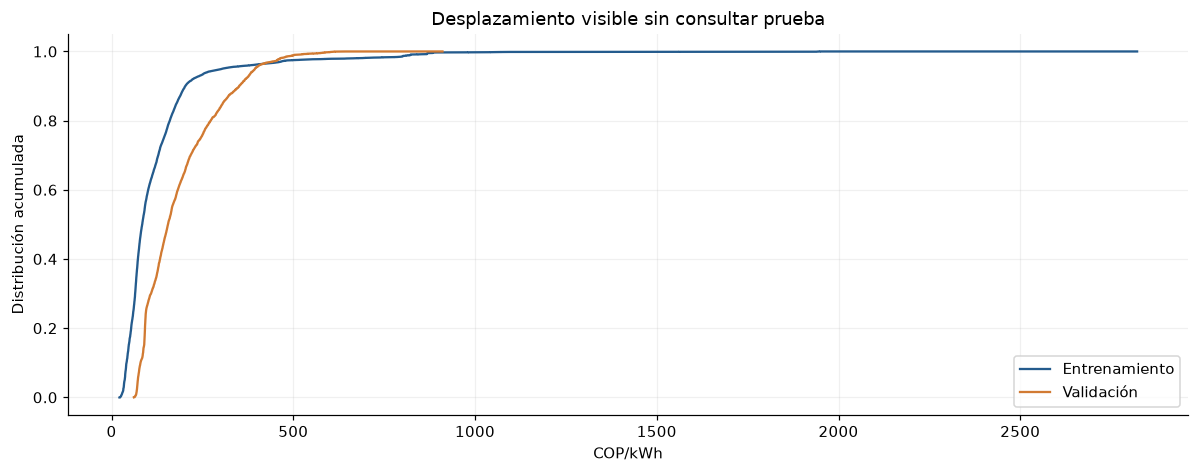

In [16]:
fig, ax = plt.subplots()
for name, frame in [('Entrenamiento', train), ('Validación', valid)]:
    x = np.sort(frame[TARGET].to_numpy())
    ax.plot(x, np.arange(1, len(x) + 1) / len(x), label=name)
ax.set(xlabel='COP/kWh', ylabel='Distribución acumulada', title='Desplazamiento visible sin consultar prueba')
ax.legend()
figure(fig, 'shift_train_validacion')

In [17]:
calendar = pd.date_range('2000-01-01', '2026-01-01', freq='h', inclusive='left', tz='America/Bogota')
origins = calendar[168:-23]
origins = origins[origins.hour == 0]
labels = collections.Counter((split_for_labels(t, t + pd.Timedelta(hours=24)) for t in origins))
table(pd.Series(labels, name='origenes_candidatos_calendario').to_frame(), 'ventanas_calendario_sin_leer_prueba')

,origenes_candidatos_calendario
train,6568
validation,1461
test,1461


In [18]:
tests = []
verify_guards()
try:
    load_numeric('test')
except PermissionError:
    tests.append(('carga de prueba bloqueada por defecto', True))
else:
    raise AssertionError('Test access allowed')
assert split_for_labels('2017-12-31T12:00:00-05:00', '2018-01-01T12:00:00-05:00') == 'purged'
tests.append(('horizonte que cruza corte eliminado', True))
table(pd.DataFrame(tests, columns=['control', 'pasa']).set_index('control'), 'controles_fuga')

OK: versiones, captura, fechas futuras, supuestos, fuentes excluidas y zona horaria.


,pasa
control,
carga de prueba bloqueada por defecto,True
horizonte que cruza corte eliminado,True


In [19]:
display(Markdown('El estadístico KS se presenta sin su p-valor IID: los días son dependientes. Wasserstein es un tamaño de desplazamiento, no prueba causal. El bootstrap de bloques conserva dependencia local y presupone estabilidad aproximada dentro de cada periodo; no corrige cambios estructurales por sí solo. Las ventanas se cuentan desde el calendario, sin leer los valores de prueba.'))

El estadístico KS se presenta sin su p-valor IID: los días son dependientes. Wasserstein es un tamaño de desplazamiento, no prueba causal. El bootstrap de bloques conserva dependencia local y presupone estabilidad aproximada dentro de cada periodo; no corrige cambios estructurales por sí solo. Las ventanas se cuentan desde el calendario, sin leer los valores de prueba.

In [20]:
decision('Ajustar toda transformación sólo con train. Si se recalibra con origen móvil, usar únicamente datos anteriores al origen y una política cerrada antes de prueba.', 'Comparar capacidad de adaptación de modelos con el mismo presupuesto; no seleccionar una red con estas estadísticas de validación.', 'Prueba congelada; sólo integridad/calendario/cobertura. Contexto pasado puede atravesar el corte, etiquetas futuras no. Origen es inicio del intervalo a pronosticar.', 'El uso exploratorio de validación y la incertidumbre sobre disponibilidad y revisiones deben incorporarse a la interpretación de la evaluación predictiva.')

### Implicaciones del análisis

- **Preprocesamiento:** Ajustar toda transformación sólo con train. Si se recalibra con origen móvil, usar únicamente datos anteriores al origen y una política cerrada antes de prueba.
- **Arquitectura:** Comparar capacidad de adaptación de modelos con el mismo presupuesto; no seleccionar una red con estas estadísticas de validación.
- **Validación:** Prueba congelada; sólo integridad/calendario/cobertura. Contexto pasado puede atravesar el corte, etiquetas futuras no. Origen es inicio del intervalo a pronosticar.
- **Riesgos:** El uso exploratorio de validación y la incertidumbre sobre disponibilidad y revisiones deben incorporarse a la interpretación de la evaluación predictiva.